<center> <span style="color:indigo">Métodos Estadísticos Básicos</span> </center> 

<img src="imagenes/MCD.jpg" alt="Drawing" style="width: 600px;"/>

<center> <span style="color:DarkBlue">  Estadística Inferencial: Tarea 3, Clustering </span>  </center>
<center> <span style="color:Blue"> M. en C. Iván A. Toledano Juárez </span>  </center>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns


from scipy.cluster.hierarchy import dendrogram, linkage, cut_tree

%matplotlib inline

#%matplotlib qt

## Importación de datos

Este set de datos contiene transacciones ocurridas entre los años 2010 y 2011 para una empresa de e-commerce localizada en Reino Unido. El origen del set de datos puede ser consultado [aqui](https://archive.ics.uci.edu/dataset/352/online+retail).

Este set de datos tiene las siguientes variables:

* InvoiceNo (categórico)
* StockCode (categórico)
* Description (categórico)
* Quantity (numérico Entero)
* InvoiceDate (Fecha)
* UnitPrice (numérico Real)
* CustomerID (categórico)
* Country (categórico)

Basado en ejercicio de [Kaggle](https://www.kaggle.com/code/hellbuoy/online-retail-k-means-hierarchical-clustering)

In [2]:
filename = "Datasets/OnlineRetail.csv"
data = pd.read_csv(filename,
                 sep = ",",
                 encoding = "ISO-8859-1")
data.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
data.shape
# Hay 541909 observaciones en el set de datos

(541909, 8)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [6]:
data.isnull().sum()
# Hay algunos valores nulos en la variable description y Customer ID

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
# Eliminamos filas que contengan algún valor nulo
data_retail = data.dropna(how='any')
data_retail.shape

(406829, 8)

## Elección de variables

En este ejemplo, se hace el clustering utilizando 3 variables:

* Número de días desde la última compra (Recency)
* Número de transacciones (Frequency)
* Cantidad Total gastada en las transacciones por cliente (Amount)

El análisis RFM(Recency, Frequency, Monetary) es una técnica utilizada en marketing y análisis de datos para evaluar el comportamiento de un cliente basado en estos tres factores. Los clientes son agrupados basados en estas tres variables, y esta información ayuda a identificar segmentos clave como los mejores clientes, clientes en riesgo de abandonar las compras, clientes leales potenciales, etc. y con esto poder tener estrategias de marketing más personalizadas. 

In [12]:
## Columna: Cantidad Total de transacciones

data_retail['Total_amount'] = data_retail['Quantity'] * data_retail['UnitPrice']

# Crear un nuevo dataframe donde se agrupa todo el total por mismo CustomerID
data_m = data_retail.groupby('CustomerID')['Total_amount'].sum()
data_m = data_m.reset_index() # se resetea el índice del data frame
data_m.head(5)

/var/folders/ls/3cpc9bjx04xfmf_tzhgzfgrm0000gn/T/ipykernel_40047/308657098.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_retail['Total_amount'] = data_retail['Quantity'] * data_retail['UnitPrice']


,CustomerID,Total_amount
0,12346.0,0.00
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40


In [13]:
## Columna: Número de transacciones por cliente (frecuencia)

data_f = data_retail.groupby('CustomerID')['InvoiceNo'].count() # Se cuenta el numero de veces que compra un cliente
data_f = data_f.reset_index() # se resetea el índice del data frame
data_f.head(5)

,CustomerID,InvoiceNo
0,12346.0,2
1,12347.0,182
2,12348.0,31
3,12349.0,73
4,12350.0,17


In [14]:
### Se hace un inner join de esta información en un nuevo dataframe

data_retail_2 = pd.merge(data_m, data_f,
                         on = 'CustomerID',
                         how = 'inner')
data_retail_2.head(5)

,CustomerID,Total_amount,InvoiceNo
0,12346.0,0.00,2
1,12347.0,4310.00,182
2,12348.0,1797.24,31
3,12349.0,1757.55,73
4,12350.0,334.40,17


La variable **InvoiceDate** no se encuentra originalmente como una variable de fecha, así que se tiene que cambiar. Una variable de tipo datetime de pandas tiene los atributos de año, mes y día.

In [16]:
## Columna: días después de la última compra
## Se tiene que especificar qué formato tenía originalmente la información

data_retail['InvoiceDate'] = pd.to_datetime(data_retail['InvoiceDate'],
                                            format = '%m/%d/%Y %H:%M')
data_retail.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 406829 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     406829 non-null  object        
 1   StockCode     406829 non-null  object        
 2   Description   406829 non-null  object        
 3   Quantity      406829 non-null  int64         
 4   InvoiceDate   406829 non-null  datetime64[ns]
 5   UnitPrice     406829 non-null  float64       
 6   CustomerID    406829 non-null  float64       
 7   Country       406829 non-null  object        
 8   Total_amount  406829 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 31.0+ MB


/var/folders/ls/3cpc9bjx04xfmf_tzhgzfgrm0000gn/T/ipykernel_40047/1815875629.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_retail['InvoiceDate'] = pd.to_datetime(data_retail['InvoiceDate'],


In [17]:
## Columna: numéro de días después de la última transaccion, por cliente

# Fecha más reciente en el dataset
max_date = max(data_retail['InvoiceDate'])
print('Fecha más reciente = ', max_date) # Esta fecha se usa como referencia para variable Recency

# Diferencia entre la fecha más reciente y la fecha de las transacciones
# La mínima de estas fechas, por cliente único, nos dice los días de la última transaccion
data_retail['Diff'] = max_date - data_retail['InvoiceDate']

# Se hace un dataframe con los dias de la última transaccion, por cliente único

data_p = data_retail.groupby('CustomerID')['Diff'].min()
data_p = data_p.reset_index()
data_p.head(5)

Fecha más reciente =  2011-12-09 12:50:00


/var/folders/ls/3cpc9bjx04xfmf_tzhgzfgrm0000gn/T/ipykernel_40047/1658946998.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_retail['Diff'] = max_date - data_retail['InvoiceDate']


,CustomerID,Diff
0,12346.0,325 days 02:33:00
1,12347.0,1 days 20:58:00
2,12348.0,74 days 23:37:00
3,12349.0,18 days 02:59:00
4,12350.0,309 days 20:49:00


Esta diferencia es de tipo deltatime. Tenemos que cambiarla a variable numérica nuevamente para utilizar el algoritmo de clustering.

In [18]:
# Se extrae únicamente los días con métodos dt de Pandas
data_p['Diff'] = data_p['Diff'].dt.days
data_p.head(5)

,CustomerID,Diff
0,12346.0,325
1,12347.0,1
2,12348.0,74
3,12349.0,18
4,12350.0,309


In [19]:
# Se hace un inner join con el dataframe de frecuencia y total amount

data_retail_3 = pd.merge(data_retail_2, data_p,
                         on = 'CustomerID',
                         how = 'inner')

# Renombrar columnas
data_retail_3.columns = ['CustomerID', 'Amount', 'Frequency', 'Recency']
data_retail_3.head(5)

,CustomerID,Amount,Frequency,Recency
0,12346.0,0.00,2,325
1,12347.0,4310.00,182,1
2,12348.0,1797.24,31,74
3,12349.0,1757.55,73,18
4,12350.0,334.40,17,309


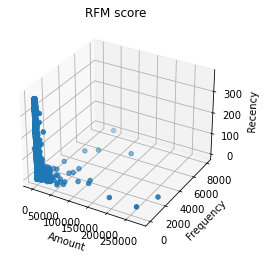

In [24]:
# Plot 3d de los datos
#%matplotlib qt


fig = plt.figure()

ax = fig.add_subplot(111,
                     projection='3d')

ax.scatter(xs=data_retail_3['Amount'],
             ys=data_retail_3['Frequency'],
             zs=data_retail_3['Recency'])
ax.set_xlabel('Amount')
ax.set_ylabel('Frequency')
ax.set_zlabel('Recency')
ax.set_title('RFM score')

plt.show()

Sobre este nuevo dataframe es donde se realizará el clustering, utilizando estas tres variables sugeridas, para cada CustomerID único. A continuación, se remueven valores atípicos.

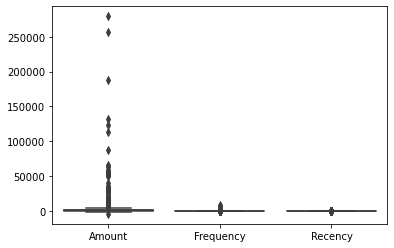

In [25]:
# Boxplot

sns.boxplot(data = data_retail_3[['Amount', 'Frequency', 'Recency']],
            orient = 'v')

plt.show()

Vemos que hay algunos valores atípicos, sobre todo en el gasto total por cliente. En este ejemplo, utilizan los cuantiles 5 (q_min) y 95 (q_max) para definir un rango IQR = q_max - q_min. Cualquier valor fuera del rango $(q_{\rm min} - 1.5\cdot{\rm IQR}, \ q_{\rm max} + 1.5\cdot{\rm IQR})$ es considerado valor atípico y no se considera en el análisis.

In [26]:
# Valores atípicos

# Variable Amount
q_min = data_retail_3.Amount.quantile(0.05)
q_max = data_retail_3.Amount.quantile(0.95)
IQR = q_max - q_min
data_retail_4 = data_retail_3[(data_retail_3.Amount >= q_min - 1.5*IQR) & \
                              (data_retail_3.Amount <= q_max + 1.5*IQR)]

# Variable Frequency
q_min = data_retail_4.Frequency.quantile(0.05)
q_max = data_retail_4.Frequency.quantile(0.95)
IQR = q_max - q_min
data_retail_4 = data_retail_4[(data_retail_4.Frequency >= q_min - 1.5*IQR) & \
                              (data_retail_4.Frequency <= q_max + 1.5*IQR)]

# Variable Recency
q_min = data_retail_4.Recency.quantile(0.05)
q_max = data_retail_4.Recency.quantile(0.95)
IQR = q_max - q_min
data_retail_4 = data_retail_4[(data_retail_4.Recency >= q_min - 1.5*IQR) & \
                              (data_retail_4.Recency <= q_max + 1.5*IQR)]

data_retail_4.head(5)

,CustomerID,Amount,Frequency,Recency
0,12346.0,0.00,2,325
1,12347.0,4310.00,182,1
2,12348.0,1797.24,31,74
3,12349.0,1757.55,73,18
4,12350.0,334.40,17,309


In [27]:
# Shape antes y despues
print('Shape antes = ', data_retail_3.shape)
print('Shape despues = ', data_retail_4.shape)

# Se han ignorado algunos valores atípicos

Shape antes =  (4372, 4)
Shape despues =  (4293, 4)


Las variables a utilizar no tienen la misma escala, por lo que se tienen que normalizar para no tener sesgos en la distancia utilizada en el clustering.

In [28]:
# Mantenemos este dataframe que ya no contiene valores atipicos
df = data_retail_4.copy()
df.head(5)

,CustomerID,Amount,Frequency,Recency
0,12346.0,0.00,2,325
1,12347.0,4310.00,182,1
2,12348.0,1797.24,31,74
3,12349.0,1757.55,73,18
4,12350.0,334.40,17,309


In [30]:
# Normalizacion de datos
# Tener valores entre 0 y 1 (Excepto en la variable CustomerID, esa queda igual)

attributes = ['Amount', 'Frequency', 'Recency']


df_norm = (data_retail_4[attributes] - data_retail_4[attributes].min()) / \
     (data_retail_4[attributes].max() - data_retail_4[attributes].min())

# Opcional (se vuelve a añadir la variable CustomerID)
#df = pd.DataFrame.join(data_retail_4.CustomerID.to_frame(), df,
#                       how = 'left')

df_norm.head(100)

,Amount,Frequency,Recency
0,0.238663,0.001395,0.871314
1,0.478571,0.252441,0.002681
2,0.338703,0.041841,0.198391
3,0.336494,0.100418,0.048257
4,0.257277,0.022315,0.828418
...,...,...,...
96,0.311227,0.121339,0.120643
97,0.306129,0.039052,0.024129
98,0.279513,0.069735,0.018767
99,0.278965,0.054393,0.380697


El último dataframe ``df_norm`` es el que se va a utilizar en el modelo. Además de las tres variables de interés sin valores atípicos, también se considera la una normalización **min-max**.

# Clustering jerárquico
Se elige una métrica euclídea con un método de enlace de Ward.


In [31]:
# Indicamos el tipo de métrica y enlace
# Se realiza el agrupamiento

Z = linkage(df_norm,
            method="ward",
            metric='euclidean')

In [32]:
# Funcion de Dendograma detallado

def dendrogram_detailed(*args, **kwargs):
    max_d = kwargs.pop("max_d", None) ## la maxima distancia de los argumentos
    if max_d  and 'color_threshold' not in kwargs:
        kwargs['color_threshold'] = max_d
    annotate_above = kwargs.pop("annotate_above", 0)
    
    ddata = dendrogram(*args, **kwargs)
    
    if not kwargs.get('no_plot', False):
        plt.title('Clustering jerárquico (Detallado)')
        plt.xlabel("Índice del DataSet (o tamaño del cluster)")
        plt.ylabel("Distancia")
        for index, distance, color in zip(ddata['icoord'], ddata['dcoord'], ddata['color_list']):
            x = 0.5 * sum(index[1:3])
            y = distance[1] # la altura
            if y>annotate_above:
                plt.plot(x,y,'o',c=color)
                plt.annotate('%.3g'%y, (x,y), xytext=(0,-5),
                            textcoords='offset points', va='top', ha="center")
    if max_d:
        plt.axhline(y=max_d, c='k')
        
    return ddata

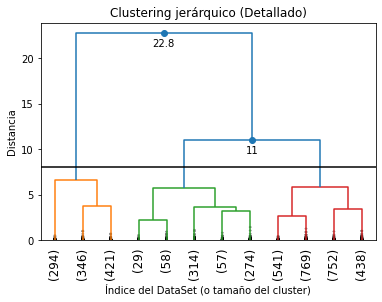

In [33]:
# Visualizamos el dendograma

dendrogram_detailed(Z,truncate_mode='lastp',p=12, leaf_rotation=90.0,leaf_font_size=12.0,
                   show_contracted=True, annotate_above=10, max_d = 8.0)
plt.show()

Vemos que posiblemente hay tres clusters. Utilizamos el método del codo para decidir.

In [35]:
# se fija en la aceleración del cambio
# nos quedamos con los últimos registros
last = Z[-10:,2] # nos quedamos solo con las distancias (índice 2), y los últimos 10 registros
last_rev = last[::-1] # la reversa del array
last_rev

array([22.76781726, 10.97092263,  6.64056922,  5.89687568,  5.71983871,
        3.77244211,  3.62697078,  3.40658433,  3.17258933,  2.65921361])

In [36]:
# tomamos indices
idx = np.arange(1,len(last) + 1)

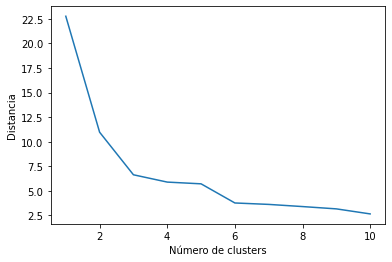

In [37]:
plt.plot(idx,last_rev)
plt.ylabel('Distancia')
plt.xlabel('Número de clusters')
plt.show()

Fuera del 'bump' en el índice 5, parece ser que una elección de 3 clusters es decente.

El método ``cut_tree`` de _scipy.cluster.hierarchy_ nos permite hacer este corte a tres clusters.



In [38]:
# 3 clusters
cluster_labels = cut_tree(Z, n_clusters=3).reshape(-1, )
cluster_labels

array([0, 1, 2, ..., 0, 2, 2])

In [39]:
# Dataframe para clustering jerarquico
# Añadimos las etiquetas de cada cluster

df_h = df.copy()

df_h['Cluster_Labels'] = cluster_labels
df_h.head(5)

,CustomerID,Amount,Frequency,Recency,Cluster_Labels
0,12346.0,0.00,2,325,0
1,12347.0,4310.00,182,1,1
2,12348.0,1797.24,31,74,2
3,12349.0,1757.55,73,18,2
4,12350.0,334.40,17,309,0


Ahora ya tenemos las etiquetas asociadas a cada observación. Ahora vemos cómo es la estadística de cada uno de los clusters identificados.

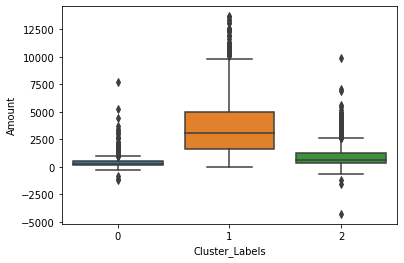

In [40]:
sns.boxplot(data = df_h,
            x = 'Cluster_Labels',
            y = 'Amount')
plt.show()

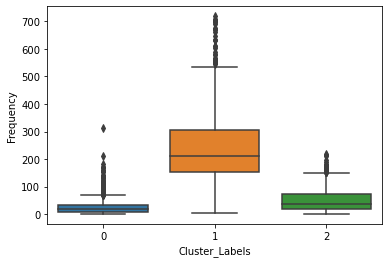

In [41]:
sns.boxplot(data = df_h,
            x = 'Cluster_Labels',
            y = 'Frequency')
plt.show()

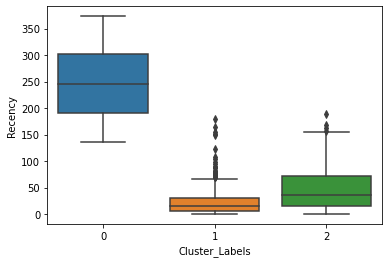

In [42]:
sns.boxplot(data = df_h,
            x = 'Cluster_Labels',
            y = 'Recency')
plt.show()

In [43]:
# Estadisticas por cluster

df_h.groupby('Cluster_Labels').mean()

,CustomerID,Amount,Frequency,Recency
Cluster_Labels,,,,
0,15348.081998,429.372536,27.089538,249.377003
1,15285.345628,3728.130943,248.430328,22.516393
2,15283.714400,907.728121,48.817600,46.496000


# Clustering con k-medias

In [45]:
from sklearn.cluster import KMeans
from sklearn import datasets

In [46]:
model = KMeans(n_clusters=3,
               max_iter = 50)
model.fit(df_norm)

KMeans(max_iter=50, n_clusters=3)

In [47]:
# podemos ver que observaciones pertenecen a cada uno de los clusters

model.labels_

array([0, 2, 1, ..., 0, 1, 1], dtype=int32)

In [48]:
# Dataframe para clustering con k medias
df_k = df.copy()

# Incluimos los modelos generados (hierarchy y kmeans) en el dataset normalizado
df_k['Cluster_Labels'] = model.labels_

df_k.head(5)

,CustomerID,Amount,Frequency,Recency,Cluster_Labels
0,12346.0,0.00,2,325,0
1,12347.0,4310.00,182,1,2
2,12348.0,1797.24,31,74,1
3,12349.0,1757.55,73,18,1
4,12350.0,334.40,17,309,0


In [49]:
# Estadistica por cluster

df_k.groupby('Cluster_Labels').mean()

,CustomerID,Amount,Frequency,Recency
Cluster_Labels,,,,
0,15369.427488,440.003480,27.302370,250.134597
1,15285.407177,976.235193,56.680703,45.597949
2,15233.295858,4582.987041,293.960552,17.536489


# Utilizando normalizacion standard

La normalización de este tipo supone que la variable tiene una distribución como una curva normal estándar (media $\mu$ = 0, desviación estándar $\sigma$ = 1) y asigna un valor acorde a esta distribución (z-valor) $z = \frac{x - \mu}{\sigma}$.

In [44]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# Reescalamiento de variables

df_norm_std = df[['Amount', 'Frequency', 'Recency']]

# Se utiliza el método StandardScaler de Scikit learn para generar esta distribución
scaler = StandardScaler()

# Se aplica la transformación a los datos según esta distribución normal estándar
df_norm_std = scaler.fit_transform(df_norm_std)
df_norm_std.shape


(4293, 3)

In [37]:
df_norm_std = pd.DataFrame(df_norm_std)
df_norm_std.columns = ['Amount', 'Frequency', 'Recency']
df_norm_std.head()

,Amount,Frequency,Recency
0,-0.723738,-0.752888,2.301611
1,1.731617,1.042467,-0.906466
2,0.300128,-0.463636,-0.183658
3,0.277517,-0.044720,-0.738141
4,-0.533235,-0.603275,2.143188


## Clustering jerárquico (standard normalization)

In [38]:
# Generamos los enlaces (se utiliza metodo de enlace average)
Z = linkage(df_norm_std,"average",
            metric = 'euclidean')

In [39]:
# Funcion de Dendograma detallado

def dendrogram_detailed(*args, **kwargs):
    max_d = kwargs.pop("max_d", None) ## la maxima distancia de los argumentos
    if max_d  and 'color_threshold' not in kwargs:
        kwargs['color_threshold'] = max_d
    annotate_above = kwargs.pop("annotate_above", 0)
    
    ddata = dendrogram(*args, **kwargs)
    
    if not kwargs.get('no_plot', False):
        plt.title('Clustering jerárquico (Detallado)')
        plt.xlabel("Índice del DataSet (o tamaño del cluster)")
        plt.ylabel("Distancia")
        for index, distance, color in zip(ddata['icoord'], ddata['dcoord'], ddata['color_list']):
            x = 0.5 * sum(index[1:3])
            y = distance[1] # la altura
            if y>annotate_above:
                plt.plot(x,y,'o',c=color)
                plt.annotate('%.3g'%y, (x,y), xytext=(0,-5),
                            textcoords='offset points', va='top', ha="center")
    if max_d:
        plt.axhline(y=max_d, c='k')
        
    return ddata

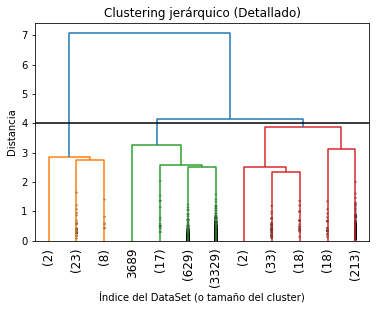

In [40]:
# Visualizamos el dendograma

dendrogram_detailed(Z,truncate_mode='lastp',p=12, leaf_rotation=90.0,leaf_font_size=12.0,
                   show_contracted=True, annotate_above=10, max_d = 4.0)
plt.show()

Vemos que posiblemente hay tres clusters. Utilizamos el método del codo para decidir.

In [41]:
# se fija en la aceleración del cambio
# nos quedamos con los últimos registros
last = Z[-10:,2] # nos quedamos solo con las distancias
last_rev = last[::-1] # la reversa del array
last_rev

array([7.06184453, 4.15219635, 3.87538552, 3.252552  , 3.13458693,
       2.86341657, 2.73242476, 2.59037261, 2.50932753, 2.49375128])

In [42]:
# tomamos indices
idx = np.arange(1,len(last) + 1)

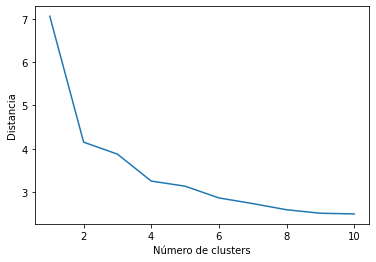

In [43]:
plt.plot(idx,last_rev)
plt.ylabel('Distancia')
plt.xlabel('Número de clusters')
plt.show()

In [44]:
# 3 clusters

cluster_labels = cut_tree(Z, n_clusters=3).reshape(-1, )
cluster_labels

array([0, 0, 0, ..., 0, 0, 0])

In [45]:
# Dataframe para clustering jerarquico
# Añadimos las etiquetas de cada cluster

df_h = df.copy()

df_h['Cluster_Labels'] = cluster_labels
df_h.head(5)

,CustomerID,Amount,Frequency,Recency,Cluster_Labels
0,12346.0,0.00,2,325,0
1,12347.0,4310.00,182,1,0
2,12348.0,1797.24,31,74,0
3,12349.0,1757.55,73,18,0
4,12350.0,334.40,17,309,0


Ahora vemos cómo es la estadística de cada uno de los clusters identificados.

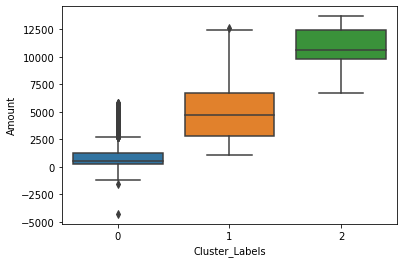

In [46]:
sns.boxplot(data = df_h,
            x = 'Cluster_Labels',
            y = 'Amount')
plt.show()

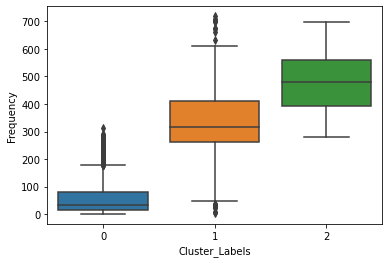

In [47]:
sns.boxplot(data = df_h,
            x = 'Cluster_Labels',
            y = 'Frequency')
plt.show()

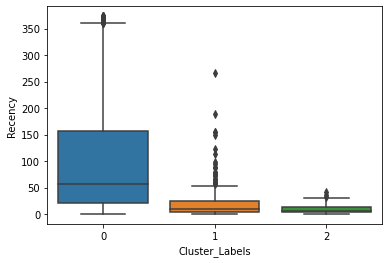

In [48]:
sns.boxplot(data = df_h,
            x = 'Cluster_Labels',
            y = 'Recency')
plt.show()

In [49]:
# Estadisticas por cluster

df_h.groupby('Cluster_Labels').mean()

,CustomerID,Amount,Frequency,Recency
Cluster_Labels,,,,
0,15306.365191,924.448987,56.577968,98.394115
1,15244.116197,5013.334261,323.197183,20.334507
2,15001.121212,10741.827576,481.666667,9.727273


## Clustering k-medias (standard normalization)

In [50]:
from sklearn.cluster import KMeans
from sklearn import datasets

In [66]:
model = KMeans(n_clusters=3,
               max_iter = 50,
               init = 'k-means++',
               tol = 0.001,
               random_state = None,
               algorithm = 'auto')
model.fit(df_norm_std)

KMeans(max_iter=50, n_clusters=3, tol=0.001)

In [67]:
# podemos ver que observaciones pertenecen a cada uno de los clusters

model.labels_

array([0, 1, 2, ..., 0, 2, 2], dtype=int32)

In [70]:
# Dataframe para clustering con k medias
df_k = df.copy()

# Incluimos los modelos generados (hierarchy y kmeans) en el dataset normalizado
df_k['Cluster_Labels'] = model.labels_

df_k.head(5)

,CustomerID,Amount,Frequency,Recency,Cluster_Labels
0,12346.0,0.00,2,325,0
1,12347.0,4310.00,182,1,1
2,12348.0,1797.24,31,74,2
3,12349.0,1757.55,73,18,2
4,12350.0,334.40,17,309,0


In [71]:
# Estadistica por cluster

df_k.groupby('Cluster_Labels').mean()

,CustomerID,Amount,Frequency,Recency
Cluster_Labels,,,,
0,15374.142322,388.568259,25.502809,248.295880
1,15096.749499,4898.735571,286.891784,21.703407
2,15308.001467,951.730177,59.516141,44.497799


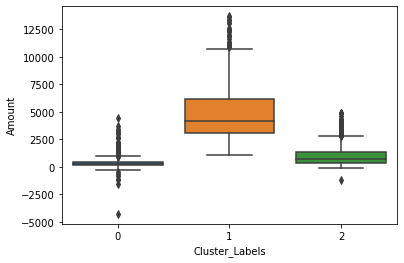

In [72]:
sns.boxplot(data = df_k,
            x = 'Cluster_Labels',
            y = 'Amount')
plt.show()

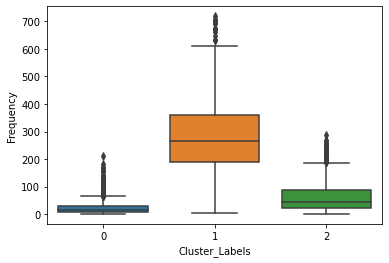

In [73]:
sns.boxplot(data = df_k,
            x = 'Cluster_Labels',
            y = 'Frequency')
plt.show()

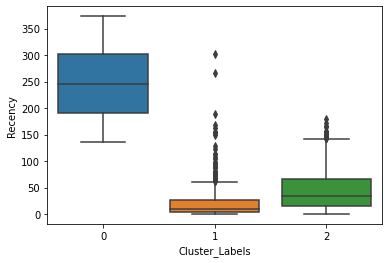

In [74]:
sns.boxplot(data = df_k,
            x = 'Cluster_Labels',
            y = 'Recency')
plt.show()

In [62]:
from sklearn.metrics import silhouette_score

# Silhouette analysis
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]

for num_clusters in range_n_clusters:
    
    # intialise kmeans
    kmeans = KMeans(n_clusters=num_clusters, max_iter=50)
    kmeans.fit(df_norm_std)
    
    cluster_labels = kmeans.labels_
    
    # silhouette score
    silhouette_avg = silhouette_score(df_norm_std, cluster_labels)
    print("For n_clusters={0}, the silhouette score is {1}".format(num_clusters, silhouette_avg))
    
    

For n_clusters=2, the silhouette score is 0.5415858652525395
For n_clusters=3, the silhouette score is 0.5084896296141937
For n_clusters=4, the silhouette score is 0.4777820100216849
For n_clusters=5, the silhouette score is 0.46627005641897035
For n_clusters=6, the silhouette score is 0.4171700614092766
For n_clusters=7, the silhouette score is 0.41752145058190115
For n_clusters=8, the silhouette score is 0.3854140447961147
